# EDA датасета RuReviews
Текущий этап — воспроизводимый EDA.

Правила воспроизводимости:
- данные читаются из `data/women-clothing-accessories.3-class.balanced.csv`;
- исходный файл не изменяется;
- случайные операции используют `SEED = 42`;
- все численные результаты получаются кодом, а не вводятся вручную;
- пути задаются относительно корня проекта;
- ключевые графики и метрики сохраняются в `reports/`.

## 0. Окружение и воспроизводимость

### Цель

Зафиксировать версии Python и библиотек, seed, пути к данным и артефактам, чтобы результаты можно было воспроизвести в чистом окружении.

In [ ]:
import hashlib
import json
import platform
import re
import sys
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split

SEED = 42
ACCESS_DATE = "2026-10-25"
SOURCE_URL = "https://github.com/sismetanin/rureviews"
SOURCE_COMMIT = "2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7"
LICENSE_NAME = "Apache-2.0"
LICENSE_URL = "https://github.com/sismetanin/rureviews/blob/2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7/LICENSE"
PAPER_DOI = "10.1109/CBI.2019.00062"
EXPECTED_SIZE = 21_781_685
EXPECTED_SHA256 = "db226708d966a1506560136ef85b33ea326eaf6119465d4b1edb5bf9395330fd"
EXPECTED_GIT_BLOB = "db9fbf29f256aadf3b80ed8c911541a8b867a2dc"
EXPECTED_ROWS = 90_000
EXPECTED_RAW_COUNTS = {"negative": 30_000, "neautral": 30_000, "positive": 30_000}
RAW_LABELS = ("negative", "positive", "neautral")
LABEL_MAP = {"negative": "negative", "positive": "positive", "neautral": "neutral"}
CLASS_ORDER = ["negative", "neutral", "positive"]

def find_project_root(start=None):
    current = (Path.cwd() if start is None else Path(start)).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Не найден pyproject.toml; запустите ноутбук из репозитория проекта")

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "women-clothing-accessories.3-class.balanced.csv"
REPORT_DIR = PROJECT_ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

PACKAGE_NAMES = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scipy",
    "scikit-learn",
    "jupyterlab",
    "ipykernel",
    "nbconvert",
    "nbformat",
]
package_versions = {}
for package in PACKAGE_NAMES:
    try:
        package_versions[package] = version(package)
    except PackageNotFoundError:
        package_versions[package] = "не установлен"

ENV = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "executable": sys.executable,
    "seed": SEED,
    "packages": package_versions,
}

def split_physical_lines(text):
    lines = re.split(r"\r\n|\r|\n", text)
    if lines and lines[-1] == "":
        lines.pop()
    return lines

def fmt_int(value):
    return f"{int(value):,}".replace(",", " ")

def fmt_pct(value):
    return f"{float(value):.1f} %"

def shorten(value, limit=160):
    text = re.sub(r"\s+", " ", str(value)).strip()
    if len(text) <= limit:
        return text
    return text[:limit].rstrip() + "…"

def preview_text(value, limit=160):
    text = shorten(value, limit)
    return re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[email]", text)

def save_figure(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

def json_default(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    raise TypeError(f"Не сериализуется тип: {type(obj)!r}")

environment_table = pd.DataFrame(
    [
        {"Параметр": "Python", "Значение": ENV["python"]},
        {"Параметр": "Платформа", "Значение": ENV["platform"]},
        {"Параметр": "Seed", "Значение": str(SEED)},
        *[{"Параметр": name, "Значение": value} for name, value in package_versions.items()],
    ]
)
display(environment_table)

,Параметр,Значение
0,Python,3.12.4
1,Платформа,Windows-11-10.0.26200-SP0
2,Seed,42
3,pandas,3.1.0
4,numpy,2.5.4
5,matplotlib,3.11.2
6,seaborn,0.13.2
7,scipy,1.18.1
8,scikit-learn,1.9.1
9,jupyterlab,4.6.4


## 1. Описание и происхождение датасета

### Цель

Установить фактический источник, версию файла, лицензию, схему полей, смысл целевой переменной и наличие исходных разбиений. Не выдавать предположения за подтверждённые факты.

In [2]:
raw_bytes = DATA_PATH.read_bytes()
raw_text = raw_bytes.decode("utf-8")
physical_lines = split_physical_lines(raw_text)
header = physical_lines[0].split("\t") if physical_lines else []
sha256 = hashlib.sha256(raw_bytes).hexdigest()
git_blob = hashlib.sha1(
    b"blob " + str(len(raw_bytes)).encode("ascii") + b"\0" + raw_bytes
).hexdigest()

format_stats = {
    "size_bytes": len(raw_bytes),
    "physical_lines": len(physical_lines),
    "crlf": raw_bytes.count(b"\r\n"),
    "lf": raw_bytes.count(b"\n"),
    "cr_only": raw_bytes.count(b"\r") - raw_bytes.count(b"\r\n"),
    "nel": raw_text.count("\u0085"),
    "bom": raw_bytes.startswith(b"\xef\xbb\xbf"),
    "replacement_char": "\ufffd" in raw_text,
}

checks = {
    "размер": len(raw_bytes) == EXPECTED_SIZE,
    "SHA-256": sha256 == EXPECTED_SHA256,
    "Git blob": git_blob == EXPECTED_GIT_BLOB,
    "заголовок": header == ["review", "sentiment"],
    "BOM отсутствует": not format_stats["bom"],
    "U+FFFD отсутствует": not format_stats["replacement_char"],
}
if not all(checks.values()):
    raise AssertionError(f"Проверка источника не пройдена: {checks}")

source_table = pd.DataFrame(
    [
        {"Параметр": "Набор данных", "Значение": "RuReviews, автоматически размеченные отзывы о товарах на русском языке"},
        {"Параметр": "Официальный URL", "Значение": SOURCE_URL},
        {"Параметр": "Файл", "Значение": DATA_PATH.name},
        {"Параметр": "Локальный путь", "Значение": str(DATA_PATH.relative_to(PROJECT_ROOT))},
        {"Параметр": "Commit master на дату обращения", "Значение": SOURCE_COMMIT},
        {"Параметр": "Дата обращения к источнику", "Значение": ACCESS_DATE},
        {"Параметр": "Лицензия", "Значение": f"{LICENSE_NAME} ({LICENSE_URL})"},
        {"Параметр": "Статья", "Значение": f"DOI {PAPER_DOI}"},
        {"Параметр": "Размер файла, байт", "Значение": fmt_int(len(raw_bytes))},
        {"Параметр": "SHA-256", "Значение": sha256},
        {"Параметр": "Git blob SHA", "Значение": git_blob},
    ]
)
display(source_table)

format_table = pd.DataFrame(
    [
        {"Показатель": "Заголовок", "Значение": " / ".join(header)},
        {"Показатель": "Физических строк", "Значение": fmt_int(format_stats["physical_lines"])},
        {"Показатель": "CRLF", "Значение": fmt_int(format_stats["crlf"])},
        {"Показатель": "LF", "Значение": fmt_int(format_stats["lf"])},
        {"Показатель": "CR без LF", "Значение": fmt_int(format_stats["cr_only"])},
        {"Показатель": "U+0085 (NEL)", "Значение": fmt_int(format_stats["nel"])},
        {"Показатель": "BOM", "Значение": "нет" if not format_stats["bom"] else "есть"},
        {"Показатель": "Символ замены U+FFFD", "Значение": "нет" if not format_stats["replacement_char"] else "есть"},
    ]
)
display(format_table)
display(
    Markdown(
        "Проверки источника: "
        + "; ".join(f"{name} — {'OK' if ok else 'ошибка'}" for name, ok in checks.items())
        + "."
    )
)

,Параметр,Значение
0,Набор данных,"RuReviews, автоматически размеченные отзывы о товарах на русском языке"
1,Официальный URL,https://github.com/sismetanin/rureviews
2,Файл,women-clothing-accessories.3-class.balanced.csv
3,Локальный путь,data\women-clothing-accessories.3-class.balanced.csv
4,Commit master на дату обращения,2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7
5,Дата обращения к источнику,2026-10-25
6,Лицензия,Apache-2.0 (https://github.com/sismetanin/rureviews/blob/2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7/LICENSE)
7,Статья,DOI 10.1109/CBI.2019.00062
8,"Размер файла, байт",21 781 685
9,SHA-256,db226708d966a1506560136ef85b33ea326eaf6119465d4b1edb5bf9395330fd


,Показатель,Значение
0,Заголовок,review / sentiment
1,Физических строк,101 893
2,CRLF,8 452
3,LF,98 453
4,CR без LF,3 440
5,U+0085 (NEL),14
6,BOM,нет
7,Символ замены U+FFFD,нет


Проверки источника: размер — OK; SHA-256 — OK; Git blob — OK; заголовок — OK; BOM отсутствует — OK; U+FFFD отсутствует — OK.

### Результат

Локальный файл совпадает с опубликованным файлом RuReviews по размеру, SHA-256 и Git blob SHA. Заголовок — `review\tsentiment`, кодировка UTF-8 без BOM, символ замены отсутствует. В текстах найдено 14 символов `U+0085` (NEL); они не являются разделителями физических строк и сохраняются в отзывах.

### Интерпретация

- Источник: RuReviews, репозиторий `https://github.com/sismetanin/rureviews`, master, commit `2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7` на дату обращения `2026-10-25`.
- Лицензия: Apache-2.0; ссылка на `LICENSE` приведена в таблице. Статья: DOI `10.1109/CBI.2019.00062`.
- В master-репозитории опубликован только balanced-файл на 90 000 записей. Заявленный в README полный набор на 821 000 отзывов в репозитории не обнаружен и не проверялся; это ограничение анализа.
- В файле два исходных столбца: `review` и `sentiment`. Исходных train/validation/test-разбиений нет.
- Фактические метки: `negative`, `neautral`, `positive`. `neautral` — опечатка; в анализе она нормализуется в `neutral` только в памяти, исходное значение сохраняется в `sentiment_raw`.
- README описывает сжатие 5-балльной шкалы в 3 класса, но формулировка противоречива: оценки 1–2 отнесены к negative, а 3 и 5 буквально — к positive, хотя заявлены три класса, включая neutral; оценка 4 не упомянута. Точное соответствие рейтингов классам помечено как «Требует проверки» и не используется как доказанный факт.
- Дата получения локальной копии не установлена; зафиксирована дата сверки с источником.

### Вывод

Для EDA используем локальный balanced-файл на 90 000 записей. Перед загрузкой проверяем его идентичность; исходный файл не изменяем. Ограничения источника и неопределённость маппинга меток фиксируем в `docs/data_provenance.md`.

## 2. Загрузка и первичная проверка

### Цель

Загрузить данные с явной кодировкой, корректно обработать многострочные отзывы и табуляцию внутри текста, проверить схему и типы, зафиксировать seed и версии.

In [3]:
def load_rureviews(path):
    lines = split_physical_lines(Path(path).read_text(encoding="utf-8"))
    if not lines:
        raise ValueError("Файл пуст")
    header_line = lines[0].split("\t")
    if header_line != ["review", "sentiment"]:
        raise ValueError(f"Неожиданный заголовок: {header_line}")
    records = []
    buffer = []
    start_line = None
    for line_number, line in enumerate(lines[1:], start=2):
        if not buffer:
            start_line = line_number
        buffer.append(line)
        if "\t" not in line:
            continue
        text_part, label = line.rsplit("\t", 1)
        label = label.strip()
        if label not in RAW_LABELS:
            continue
        buffer[-1] = text_part
        records.append(
            {
                "review": "\n".join(buffer),
                "sentiment_raw": label,
                "line_start": start_line,
                "line_end": line_number,
                "n_physical_lines": len(buffer),
            }
        )
        buffer = []
    if buffer:
        raise ValueError(f"Не удалось разобрать {len(buffer)} строк(и) в конце файла")
    frame = pd.DataFrame.from_records(records)
    frame["review"] = frame["review"].astype("string")
    frame["sentiment_raw"] = frame["sentiment_raw"].astype("string")
    frame["sentiment"] = pd.Categorical(
        frame["sentiment_raw"].map(LABEL_MAP),
        categories=CLASS_ORDER,
        ordered=False,
    )
    return frame

df = load_rureviews(DATA_PATH)
loaded_shape = df.shape
raw_label_counts = df["sentiment_raw"].value_counts().to_dict()
if len(df) != EXPECTED_ROWS:
    raise ValueError(f"Ожидалось {EXPECTED_ROWS} записей, получено {len(df)}")
if raw_label_counts != EXPECTED_RAW_COUNTS:
    raise ValueError(f"Неожиданное распределение меток: {raw_label_counts}")
if df["sentiment"].isna().any():
    raise ValueError("Есть записи без нормализованной метки")

multiline_records = int((df["n_physical_lines"] > 1).sum())
tab_records = int(df["review"].str.contains("\t", regex=False).sum())
whitespace_only = int(df["review"].str.strip().eq("").sum())
exact_empty = int(df["review"].eq("").sum())

load_summary = pd.DataFrame(
    [
        {"Показатель": "Строк", "Значение": fmt_int(len(df))},
        {"Показатель": "Столбцов в исходном файле", "Значение": 2},
        {"Показатель": "Диагностических столбцов добавлено", "Значение": loaded_shape[1] - 2},
        {"Показатель": "Многострочных записей", "Значение": fmt_int(multiline_records)},
        {"Показатель": "Записей с табуляцией в тексте", "Значение": fmt_int(tab_records)},
        {"Показатель": "Точных пустых текстов", "Значение": fmt_int(exact_empty)},
        {"Показатель": "Текстов только из пробелов", "Значение": fmt_int(whitespace_only)},
    ]
)
display(load_summary)

schema_table = pd.DataFrame(
    {
        "Столбец": df.columns,
        "dtype": [str(dtype) for dtype in df.dtypes],
        "Непустых": [int(df[column].notna().sum()) for column in df.columns],
        "Уникальных": [int(df[column].nunique(dropna=False)) for column in df.columns],
    }
)
display(schema_table)
display(Markdown(f"Форма DataFrame после загрузки: **{df.shape[0]:,} × {df.shape[1]}**.".replace(",", " ")))

preview = df.head(5).copy()
preview["review"] = preview["review"].map(preview_text)
display(preview[["review", "sentiment_raw", "sentiment", "line_start", "line_end", "n_physical_lines"]])

sample_preview = df.sample(5, random_state=SEED).copy()
sample_preview["review"] = sample_preview["review"].map(preview_text)
display(sample_preview[["review", "sentiment_raw", "sentiment", "line_start", "line_end", "n_physical_lines"]])

display(
    Markdown(
        f"Загружено **{fmt_int(len(df))}** записей. "
        f"Многострочных — **{fmt_int(multiline_records)}**, "
        f"с табуляцией — **{fmt_int(tab_records)}**, "
        f"пробельных — **{fmt_int(whitespace_only)}**."
    )
)

,Показатель,Значение
0,Строк,90 000
1,Столбцов в исходном файле,2
2,Диагностических столбцов добавлено,4
3,Многострочных записей,4 661
4,Записей с табуляцией в тексте,4
5,Точных пустых текстов,0
6,Текстов только из пробелов,1


,Столбец,dtype,Непустых,Уникальных
0,review,string,90000,87321
1,sentiment_raw,string,90000,3
2,line_start,int64,90000,90000
3,line_end,int64,90000,90000
4,n_physical_lines,int64,90000,22
5,sentiment,category,90000,3


Форма DataFrame после загрузки: **90 000 × 6**.

,review,sentiment_raw,sentiment,line_start,line_end,n_physical_lines
0,качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький ру...,negative,negative,2,2,1
1,"Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.",negative,negative,3,3,1
2,"Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем к...",negative,negative,4,4,1
3,"товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания",negative,negative,5,5,1
4,"Кофточка голая синтетика, носить не возможно.",negative,negative,6,6,1


,review,sentiment_raw,sentiment,line_start,line_end,n_physical_lines
89610,"The material is good,best design.recommend the seller.",positive,positive,101457,101457,1
12456,"Футболка синтетическая, очень жаркая, не рекомендую",negative,negative,14338,14338,1
53403,"Топ пришёл быстро где то за две недели. Жаль что размер один,качество хорошее. Но маловат. И огорчило маслянное пятно",neautral,neutral,60676,60676,1
62905,"Юбочка красивая, плотный материал,на размер 46 хорошо подошёл L.Доставка до СПб за три недели курьером на дом.Спасиб...",positive,positive,71425,71425,1
66339,"Отличная кофта, мягкая, приятная к телу. Дошла за 2 недели. Нитки не торчат, качество хорошее. Продавца рекомендую.",positive,positive,75270,75270,1


Загружено **90 000** записей. Многострочных — **4 661**, с табуляцией — **4**, пробельных — **1**.

### Результат

Загружено 90 000 логических записей. В исходном файле два столбца; после загрузки добавлены поля `sentiment_raw`, `line_start`, `line_end`, `n_physical_lines`, а `sentiment` нормализован. Форма DataFrame после загрузки — 90 000 × 6; `review` и `sentiment_raw` имеют тип `string`, `sentiment` — `category`, диагностические номера строк и число физических строк — целочисленные. Многострочных записей — 4 661, с табуляцией внутри текста — 4, полностью пробельных — 1. Восемь текстов содержат `U+0085`; это не разделитель физической строки, поэтому такие записи не считаются многострочными только из-за него.

### Интерпретация

- Файл только выглядит как обычный TSV: в отзывах встречаются неэкранированные переводы строк и табуляция. Поэтому стандартный `pd.read_csv(sep="\t")` на нём падает.
- Использован воспроизводимый парсер: строки накапливаются до строки, последнее поле которой после последнего таба равно одной из известных меток. Такой парсер является эвристикой, но его результат проверен по ожидаемым 90 000 записям и по 30 000 записей на класс.
- `line_start` и `line_end` позволяют вернуться к физическим строкам исходного файла при разборе спорных случаев.
- Исходный файл не перезаписывался.

### Вывод

Данные пригодны для EDA после проверенного парсинга. Все дальнейшие расчёты используют `df`; исходный CSV остаётся неизменным.

## 3. Качество данных и пропуски

### Цель

Для каждого поля оценить пропуски, пустые строки, уникальность, типы и специальные маркеры. Не заменять и не удалять значения автоматически.

In [4]:
review = df["review"].fillna("").astype("string")

quality_rows = []
for column in ["review", "sentiment_raw", "sentiment"]:
    series = df[column]
    missing = int(series.isna().sum())
    quality_rows.append(
        {
            "Столбец": column,
            "dtype": str(series.dtype),
            "Пропуски": missing,
            "Доля пропусков, %": round(missing / len(df) * 100, 2),
            "Уникальных": int(series.nunique(dropna=False)),
        }
    )
quality_table = pd.DataFrame(quality_rows)
display(quality_table)

def is_latin1_mojibake(value):
    if not re.search(r"[\x80-\x9f]", value):
        return False
    try:
        repaired = value.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return False
    return bool(re.search(r"[А-Яа-яЁё]", repaired))

c1_mask = review.str.contains(r"[\x80-\x9f]", regex=True, na=False)
mojibake_mask = review.map(is_latin1_mojibake).fillna(False).astype(bool)
no_cyrillic_mask = ~review.str.contains(r"[А-Яа-яЁё]", regex=True, na=False)

quality_stats = {
    "exact_empty": int(review.eq("").sum()),
    "whitespace_only": int(review.str.strip().eq("").sum()),
    "replacement_char": int(review.str.contains("\ufffd", regex=False, na=False).sum()),
    "control_chars": int(
        review.str.contains(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]", regex=True, na=False).sum()
    ),
    "zero_width_or_nbsp": int(
        review.str.contains("[\u00a0\u200b-\u200f\ufeff]", regex=True, na=False).sum()
    ),
    "html_tags": int(review.str.contains(r"<[^>]+>", regex=True, na=False).sum()),
    "urls": int(review.str.contains(r"https?://|www\.", case=False, regex=True, na=False).sum()),
    "digits": int(review.str.contains(r"\d", regex=True, na=False).sum()),
    "latin": int(review.str.contains(r"[A-Za-z]", regex=True, na=False).sum()),
    "no_cyrillic": int(no_cyrillic_mask.sum()),
    "no_cyrillic_without_mojibake": int((no_cyrillic_mask & ~mojibake_mask).sum()),
    "c1_rows": int(c1_mask.sum()),
    "mojibake_rows": int(mojibake_mask.sum()),
    "mojibake_c1_chars": int(review[mojibake_mask].str.count(r"[\x80-\x9f]").sum()),
    "short_lt_10": int((review.str.len() < 10).sum()),
    "short_lt_3": int((review.str.len() < 3).sum()),
}

special_table = pd.DataFrame(
    [
        {"Показатель": "Точные пустые строки", "Количество": quality_stats["exact_empty"]},
        {"Показатель": "Строки только из пробелов", "Количество": quality_stats["whitespace_only"]},
        {"Показатель": "Символ U+FFFD", "Количество": quality_stats["replacement_char"]},
        {"Показатель": "C1/управляющие символы (строк)", "Количество": quality_stats["control_chars"]},
        {"Показатель": "Mojibake, восстановимые (строк)", "Количество": quality_stats["mojibake_rows"]},
        {"Показатель": "NBSP/zero-width", "Количество": quality_stats["zero_width_or_nbsp"]},
        {"Показатель": "HTML-подобные теги", "Количество": quality_stats["html_tags"]},
        {"Показатель": "URL", "Количество": quality_stats["urls"]},
        {"Показатель": "Содержат цифры", "Количество": quality_stats["digits"]},
        {"Показатель": "Содержат латиницу", "Количество": quality_stats["latin"]},
        {"Показатель": "Без кириллицы", "Количество": quality_stats["no_cyrillic"]},
        {"Показатель": "Короче 10 символов", "Количество": quality_stats["short_lt_10"]},
        {"Показатель": "Короче 3 символов", "Количество": quality_stats["short_lt_3"]},
    ]
)
display(special_table)

marker_counts = {}
for marker in ["nan", "none", "null", "n/a", "-"]:
    marker_counts[marker] = int(
        review.str.fullmatch(re.escape(marker), case=False, na=False).sum()
    )
display(
    pd.DataFrame(
        [
            {"Текст": key, "Строк с полным совпадением": value}
            for key, value in marker_counts.items()
        ]
    )
)

short_rows = []
for threshold in [3, 10, 20]:
    row = {"Порог, символов": threshold, "Всего": int((review.str.len() < threshold).sum())}
    for class_name in CLASS_ORDER:
        row[class_name] = int(
            ((df["sentiment"] == class_name) & (review.str.len() < threshold)).sum()
        )
    short_rows.append(row)
display(pd.DataFrame(short_rows))

empty_records = df[df["review"].str.strip().eq("")]
if len(empty_records):
    empty_show = empty_records[["review", "sentiment_raw", "line_start", "line_end"]].copy()
    empty_show["review"] = empty_show["review"].map(preview_text)
    display(empty_show)

display(
    Markdown(
        f"Пропусков в метках — **{int(df['sentiment_raw'].isna().sum())}**, в текстах — **{int(df['review'].isna().sum())}**. "
        f"Точных пустых текстов — **{quality_stats['exact_empty']}**, только из пробелов — **{quality_stats['whitespace_only']}**. "
        f"C1-строк — **{quality_stats['c1_rows']}**, из них восстановимый mojibake — **{quality_stats['mojibake_rows']}** "
        f"(**{quality_stats['mojibake_c1_chars']}** C1-символов); "
        f"невидимые/специальные пробелы — **{quality_stats['zero_width_or_nbsp']}**, "
        f"HTML-теги — **{quality_stats['html_tags']}**, URL — **{quality_stats['urls']}**, "
        f"латиница — **{quality_stats['latin']}**."
    )
)

,Столбец,dtype,Пропуски,"Доля пропусков, %",Уникальных
0,review,string,0,0.0,87321
1,sentiment_raw,string,0,0.0,3
2,sentiment,category,0,0.0,3


,Показатель,Количество
0,Точные пустые строки,0
1,Строки только из пробелов,1
2,Символ U+FFFD,0
3,C1/управляющие символы (строк),19
4,"Mojibake, восстановимые (строк)",19
5,NBSP/zero-width,72
6,HTML-подобные теги,1
7,URL,128
8,Содержат цифры,31874
9,Содержат латиницу,14479


,Текст,Строк с полным совпадением
0,nan,0
1,none,0
2,null,0
3,n/a,0
4,-,13


,"Порог, символов",Всего,negative,neutral,positive
0,3,187,31,85,71
1,10,1451,250,529,672
2,20,5147,1116,2027,2004


,review,sentiment_raw,line_start,line_end
81917,,positive,92712,92712


Пропусков в метках — **0**, в текстах — **0**. Точных пустых текстов — **0**, только из пробелов — **1**. C1-строк — **19**, из них восстановимый mojibake — **19** (**662** C1-символов); невидимые/специальные пробелы — **72**, HTML-теги — **1**, URL — **128**, латиница — **14479**.

### Результат

В `review` и `sentiment_raw` нет `NaN`; все 90 000 меток заполнены. Есть один текст, состоящий только из пробелов. Символ `U+FFFD` не обнаружен. Найдены 19 строк с C1-символами: все 19 являются восстановимым mojibake (662 C1-символа, включая 14 `U+0085`); после перекодирования `latin-1 → UTF-8` они снова содержат кириллицу. Также найдены невидимые/специальные пробелы (72 строки), HTML-подобные фрагменты (1), URL (128), цифры (31 874) и латиница (14 479). Точных совпадений с `nan`, `none`, `null`, `n/a` нет; текст, целиком равный `-`, встречается в 13 строках.

### Интерпретация

- Пропуски как `NaN` отсутствуют, но пустой по смыслу текст есть; его нельзя автоматически считать обычным отзывом.
- 19 строк с C1-символами — это mojibake: UTF-8-байты кириллицы были ошибочно прочитаны как Latin-1 и сохранены как текст. Все 19 строк восстанавливаются обратным преобразованием `latin-1 → UTF-8`; в EDA они не исправляются, чтобы сохранить исходные данные и явно зафиксировать дефект.
- Наличие NBSP/zero-width, mojibake, HTML-подобных фрагментов и URL означает, что для будущего моделирования потребуется отдельное правило очистки; в EDA исходные тексты не изменяются.
- Латиница и цифры сами по себе не являются ошибкой: это могут быть размеры, бренды, единицы товара. Языковая принадлежность отдельным детектором не проверялась.
- Точных маркеров `nan`, `none`, `null`, `n/a` нет. Текст `-` в 13 строках нельзя автоматически считать маркером пропуска: это может быть самостоятельный короткий отзыв или пунктуация; решение требует отдельного правила.

### Вывод

Критических пропусков нет. Один пробельный текст и 19 mojibake-строк помечаем как проблемные; на этапе моделирования их нужно восстановить или исключить по явному правилу. Правила очистки текста будут отдельным решением, а не частью EDA.

## 4. Дубликаты и потенциальные пересечения

### Цель

Проверить полные дубликаты строк, дубликаты текста, одинаковый текст с разными метками и нормализованные дубликаты. Отдельно оценить риск пересечения при случайном разбиении, не используя это разбиение как финальное.

In [5]:
def normalize_text(value):
    text = str(value).lower()
    text = re.sub(r"[^0-9a-zа-яё]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["review_norm"] = df["review"].map(normalize_text).astype("string")

exact_dup_rows = int(df.duplicated(subset=["review", "sentiment_raw"]).sum())
exact_dup_groups = int(
    (df.groupby(["review", "sentiment_raw"], dropna=False).size() > 1).sum()
)
text_dup_rows = int(df.duplicated(subset=["review"]).sum())
unique_texts = int(df["review"].nunique())
label_variants = df.groupby("review", dropna=False)["sentiment_raw"].nunique()
multi_label_texts = int((label_variants > 1).sum())
norm_dup_rows = int(df.duplicated(subset=["review_norm"]).sum())
norm_dup_groups = int((df.groupby("review_norm", dropna=False).size() > 1).sum())

duplicate_table = pd.DataFrame(
    [
        {"Показатель": "Точные дубли строк (review + sentiment_raw)", "Значение": exact_dup_rows},
        {"Показатель": "Групп точных дублей строк", "Значение": exact_dup_groups},
        {"Показатель": "Дубли по тексту review", "Значение": text_dup_rows},
        {"Показатель": "Уникальных текстов", "Значение": unique_texts},
        {"Показатель": "Текстов с разными метками", "Значение": multi_label_texts},
        {"Показатель": "Дубли после нормализации", "Значение": norm_dup_rows},
        {"Показатель": "Групп после нормализации", "Значение": norm_dup_groups},
    ]
)
display(duplicate_table)

multi_examples = label_variants[label_variants > 1].sort_values(ascending=False).head(5)
multi_rows = []
for text, variants_count in multi_examples.items():
    labels = sorted(df.loc[df["review"] == text, "sentiment_raw"].unique().tolist())
    multi_rows.append(
        {
            "review": preview_text(text, 140),
            "Метки": ", ".join(labels),
            "Вариантов": int(variants_count),
        }
    )
if multi_rows:
    display(pd.DataFrame(multi_rows))

exact_examples = (
    df[df.duplicated(subset=["review", "sentiment_raw"], keep=False)]
    .groupby(["review", "sentiment_raw"], dropna=False)
    .size()
    .sort_values(ascending=False)
    .head(5)
)
exact_rows = [
    {"review": preview_text(text, 140), "Метка": label, "Повторов": int(count)}
    for (text, label), count in exact_examples.items()
]
if exact_rows:
    display(pd.DataFrame(exact_rows))

train_part, test_part = train_test_split(
    df,
    test_size=0.2,
    stratify=df["sentiment"],
    random_state=SEED,
)
train_texts = set(train_part["review"])
train_norm_texts = set(train_part["review_norm"])
test_text_overlap = int(test_part["review"].isin(train_texts).sum())
test_norm_overlap = int(test_part["review_norm"].isin(train_norm_texts).sum())
split_table = pd.DataFrame(
    [
        {
            "Совпадение": "Точный текст",
            "Строк теста с дублем в train": test_text_overlap,
            "Доля теста, %": round(test_text_overlap / len(test_part) * 100, 2),
        },
        {
            "Совпадение": "Нормализованный текст",
            "Строк теста с дублем в train": test_norm_overlap,
            "Доля теста, %": round(test_norm_overlap / len(test_part) * 100, 2),
        },
    ]
)
display(split_table)

display(
    Markdown(
        f"Точных дублей строк — **{exact_dup_rows}**; дублей текста — **{text_dup_rows}**; "
        f"текстов с разными метками — **{multi_label_texts}**; после нормализации — **{norm_dup_rows}**. "
        f"В гипотетическом stratified 80/20 split: **{test_text_overlap}** ({fmt_pct(test_text_overlap / len(test_part) * 100)}) "
        f"тестовых строк имеют точный дубль в train, **{test_norm_overlap}** "
        f"({fmt_pct(test_norm_overlap / len(test_part) * 100)}) — нормализованный. Исходных split в файле нет."
    )
)

,Показатель,Значение
0,Точные дубли строк (review + sentiment_raw),2250
1,Групп точных дублей строк,886
2,Дубли по тексту review,2679
3,Уникальных текстов,87321
4,Текстов с разными метками,388
5,Дубли после нормализации,4959
6,Групп после нормализации,1129


,review,Метки,Вариантов
0,"товар не пришел, деньги вернули","neautral, negative, positive",3
1,"товар не пришел, но деньги вернули","neautral, negative, positive",3
2,"Заказ не пришел, деньги вернули.","neautral, negative, positive",3
3,Заказ не пришел. Деньги вернули,"neautral, negative, positive",3
4,"Заказ не пришёл, деньги вернули","neautral, negative, positive",3


,review,Метка,Повторов
0,товар не пришел,negative,47
1,Товар не пришёл,negative,45
2,супер,positive,40
3,.,neautral,39
4,отлично,positive,34


,Совпадение,Строк теста с дублем в train,"Доля теста, %"
0,Точный текст,659,3.66
1,Нормализованный текст,1176,6.53


Точных дублей строк — **2250**; дублей текста — **2679**; текстов с разными метками — **388**; после нормализации — **4959**. В гипотетическом stratified 80/20 split: **659** (3.7 %) тестовых строк имеют точный дубль в train, **1176** (6.5 %) — нормализованный. Исходных split в файле нет.

### Результат

Точных дублей строк — 2 250 (886 групп), дублей текста — 2 679 (уникальных текстов — 87 321), текстов с разными метками — 388. После нормализации (нижний регистр, удаление пунктуации и сжатие пробелов) — 4 959 дублей в 1 129 группах. В гипотетическом stratified 80/20 split часть тестовых строк имеет точный или нормализованный дубль в train; точные значения приведены в таблице выше.

### Интерпретация

- Дубликаты и почти-дубликаты — существенная особенность датасета, а не единичный артефакт. Они могут быть как естественными короткими отзывами, так и повторами шаблонов.
- 388 текстов имеют разные метки: это потенциальный шум разметки и одновременно риск утечки, если одинаковые тексты попадут в train и test.
- Нормализация только для диагностики: она может объединять разные по смыслу тексты, поэтому нормализованные дубликаты не удаляются автоматически.
- Исходных разбиений нет, поэтому проверить пересечения между авторскими split невозможно. Гипотетическое разбиение показывает риск случайного split, но не является финальным решением.
- При 90 000 наблюдений даже небольшая доля пересечений может заметно повлиять на оценку качества.

### Вывод

На этапе EDA дубликаты сохраняются. Для будущего моделирования нужен group-aware split по точному или нормализованному тексту (либо обоснованная дедупликация до разбиения). Решение фиксируется отдельно; в EDA оно не применяется.

## 5. Целевая переменная и баланс классов

### Цель

Подтвердить поле метки, показать распределение классов, проверить неожиданные значения и оценить, как баланс может влиять на оценку моделей.

,Класс,Метка в файле,Количество,"Доля, %"
0,negative,negative,30000,33.33
1,neutral,neautral,30000,33.33
2,positive,positive,30000,33.33


,Метка в файле,Количество
0,negative,30000
1,positive,30000
2,neautral,30000


Неожиданные метки: **нет**. Отношение max/min: **1.00**.

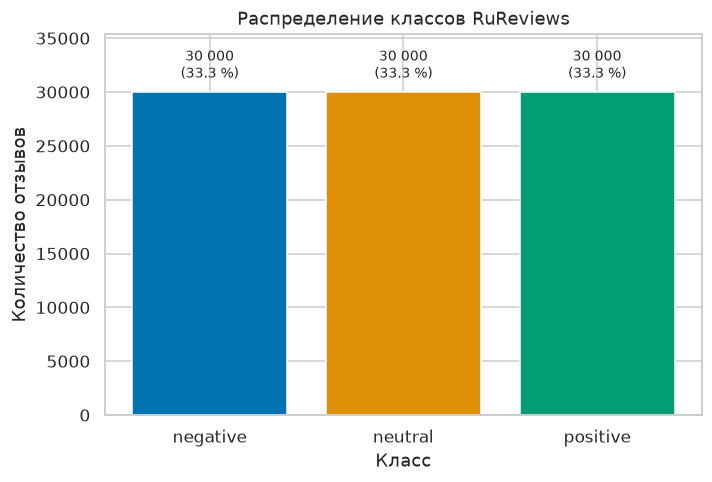

In [6]:
class_counts = df["sentiment"].value_counts().reindex(CLASS_ORDER, fill_value=0)
raw_counts = df["sentiment_raw"].value_counts().reindex(list(RAW_LABELS), fill_value=0)

balance_table = pd.DataFrame(
    {
        "Класс": CLASS_ORDER,
        "Метка в файле": ["negative", "neautral", "positive"],
        "Количество": [int(class_counts[class_name]) for class_name in CLASS_ORDER],
        "Доля, %": [
            round(float(class_counts[class_name]) / len(df) * 100, 2)
            for class_name in CLASS_ORDER
        ],
    }
)
display(balance_table)
display(
    pd.DataFrame(
        {
            "Метка в файле": raw_counts.index.tolist(),
            "Количество": raw_counts.values.astype(int),
        }
    )
)

unexpected_labels = sorted(
    set(df["sentiment_raw"].dropna().unique().tolist()) - set(RAW_LABELS)
)
balance_ratio = float(class_counts.max() / class_counts.min())
display(
    Markdown(
        f"Неожиданные метки: **{unexpected_labels if unexpected_labels else 'нет'}**. "
        f"Отношение max/min: **{balance_ratio:.2f}**."
    )
)

colors = sns.color_palette("colorblind", len(CLASS_ORDER))
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    CLASS_ORDER,
    [int(class_counts[class_name]) for class_name in CLASS_ORDER],
    color=colors,
)
for bar, class_name in zip(bars, CLASS_ORDER):
    value = int(class_counts[class_name])
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(df) * 0.01,
        f"{fmt_int(value)}\n({fmt_pct(value / len(df) * 100)})",
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.set_title("Распределение классов RuReviews")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество отзывов")
ax.set_ylim(0, int(class_counts.max()) * 1.18)
save_figure(fig, "01_class_balance.png")
plt.show()

### Результат

В файле по 30 000 записей на каждый класс; доли — по 33.3 %, отношение max/min — 1.00. Неожиданных меток после нормализации нет. Исходная метка `neautral` встречается ровно 30 000 раз.

### Интерпретация

- Идеальный баланс — результат undersampling’а, описанного в README, а не оценка естественной распространённости классов. Переносить доли на генеральную совокупность нельзя.
- Класс `neutral` связан со средней частью 5-балльной шкалы, но точное соответствие оценок 3/4/5 классам в README неполное и требует проверки. В файле метки хранятся как категориальные, без рейтинга; порядковую природу можно учитывать отдельно после уточнения маппинга.
- При балансе accuracy менее подвержена смещению, чем на несбалансированных данных, но всё равно недостаточна: нужны macro-F1 и per-class precision/recall.
- Наличие трёх классов и дисбаланса после будущего обогащения надо проверять заново: синтетические данные могут изменить распределение.

### Вывод

Целевая переменная — `sentiment` с тремя классами. Для последующей оценки используем macro-F1 и метрики по классам; доли классов не интерпретируем как естественные.

## 6. Анализ длины текста

### Цель

Описать длину отзывов в символах и whitespace-токенах, найти выбросы, пустые и очень короткие тексты, сравнить распределения по классам. Не обрезать исходные тексты.

,n,mean,std,min,p05,p25,median,p75,p95,p99,max,skew,kurtosis
char_len,90000.0,130.13,126.19,1.0,18.0,51.0,92.0,164.0,372.0,648.0,1010.0,2.63,9.85


,n,mean,std,min,p05,p25,median,p75,p95,p99,max
sentiment,,,,,,,,,,,
negative,30000,144.76,140.42,1,24.0,58.0,99.0,180.0,422.0,744.01,1004
neutral,30000,125.88,125.83,1,16.0,45.0,87.0,160.0,373.0,633.01,1010
positive,30000,119.75,108.99,1,16.0,49.0,89.0,154.0,325.0,549.01,1008


,n,mean,std,min,median,p95,max
sentiment,,,,,,,
negative,30000,22.46,22.12,1,15.0,66.0,192
neutral,30000,19.59,19.91,1,13.0,59.0,193
positive,30000,17.98,17.04,0,13.0,50.0,174


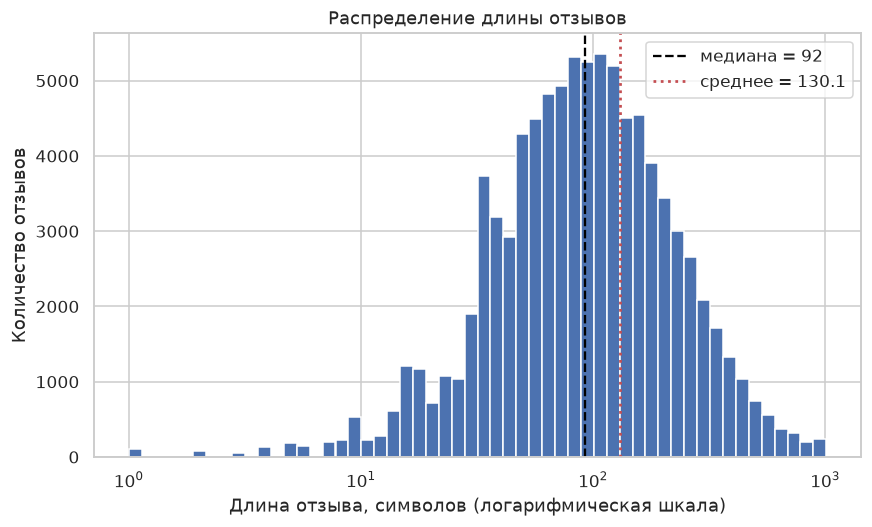

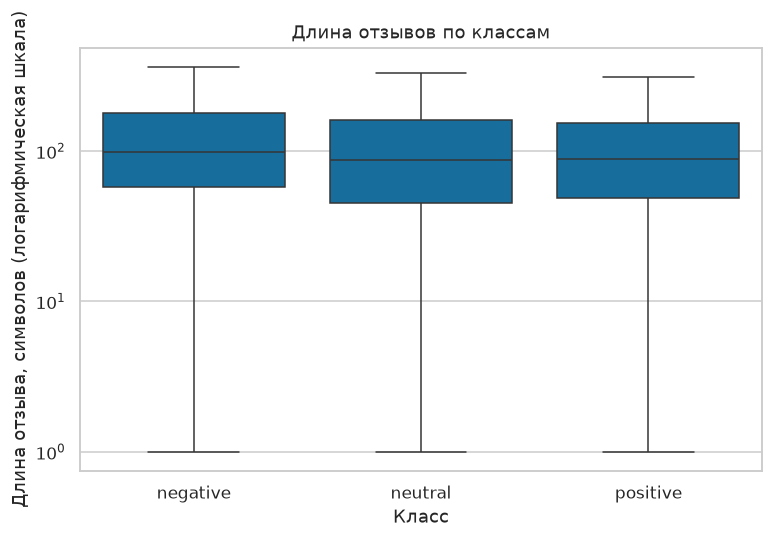

,review,sentiment_raw,char_len
39575,"""При пошиве пальто в плечо (состоит из узкого треугольника) не вложили пух - ВООБЩЕ! Я думала, что пух осел в нижний...",neautral,1010
74634,"""Наконец!!!Дождались!!!(но в этом сезоне уже не успели одеть(((! ) Заказ от 22сентября.Отправлено через неделю после...",positive,1008
7631,"""Такого мудака продавца ещё не встречала на Али.Написала продавцу чтобы посоветоваться по поводу размера.Написала па...",negative,1004
16526,"""Заявлен """"one size"""",а пришел пакет с биркой XL.Далеко не средний размер,особенно если учесть,что у меня S (ОТ66, О...",negative,1004
61124,"""Пальто по размеру, продавец замерял по моим параметрам. На вид достаточно теплое. Воротник не позорный, нормальный ...",positive,1003


Длина в символах: min **1**, медиана **92**, среднее **130.1**, max **1010**. Медианы по классам: negative **99**, neutral **87**, positive **89**.

In [7]:
df["char_len"] = df["review"].str.len()
df["word_count_ws"] = df["review"].str.split().str.len().fillna(0).astype(int)

def describe_numeric(series):
    values = series.dropna()
    return pd.Series(
        {
            "n": int(values.size),
            "mean": float(values.mean()),
            "std": float(values.std()),
            "min": float(values.min()),
            "p05": float(values.quantile(0.05)),
            "p25": float(values.quantile(0.25)),
            "median": float(values.median()),
            "p75": float(values.quantile(0.75)),
            "p95": float(values.quantile(0.95)),
            "p99": float(values.quantile(0.99)),
            "max": float(values.max()),
        }
    )

length_overall = describe_numeric(df["char_len"]).to_frame().T
length_overall.index = ["char_len"]
length_overall["skew"] = float(stats.skew(df["char_len"], bias=False))
length_overall["kurtosis"] = float(stats.kurtosis(df["char_len"], bias=False))
display(length_overall.round(2))

by_class = (
    df.groupby("sentiment", observed=True)["char_len"]
    .agg(
        n="size",
        mean="mean",
        std="std",
        min="min",
        p05=lambda values: values.quantile(0.05),
        p25=lambda values: values.quantile(0.25),
        median="median",
        p75=lambda values: values.quantile(0.75),
        p95=lambda values: values.quantile(0.95),
        p99=lambda values: values.quantile(0.99),
        max="max",
    )
    .reindex(CLASS_ORDER)
)
display(by_class.round(2))

words_by_class = (
    df.groupby("sentiment", observed=True)["word_count_ws"]
    .agg(
        n="size",
        mean="mean",
        std="std",
        min="min",
        median="median",
        p95=lambda values: values.quantile(0.95),
        max="max",
    )
    .reindex(CLASS_ORDER)
)
display(words_by_class.round(2))

max_char = int(df["char_len"].max())
bins = np.logspace(0, np.log10(max_char + 1), 55)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["char_len"], bins=bins, color="#4C72B0", edgecolor="white")
ax.set_xscale("log")
ax.axvline(
    float(df["char_len"].median()),
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"медиана = {df['char_len'].median():.0f}",
)
ax.axvline(
    float(df["char_len"].mean()),
    color="#C44E52",
    linestyle=":",
    linewidth=1.8,
    label=f"среднее = {df['char_len'].mean():.1f}",
)
ax.set_title("Распределение длины отзывов")
ax.set_xlabel("Длина отзыва, символов (логарифмическая шкала)")
ax.set_ylabel("Количество отзывов")
ax.legend()
save_figure(fig, "02_text_length_hist.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="sentiment",
    y="char_len",
    order=CLASS_ORDER,
    showfliers=False,
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("Длина отзывов по классам")
ax.set_xlabel("Класс")
ax.set_ylabel("Длина отзыва, символов (логарифмическая шкала)")
save_figure(fig, "03_text_length_by_class.png")
plt.show()

longest = df.nlargest(5, "char_len")[["review", "sentiment_raw", "char_len"]].copy()
longest["review"] = longest["review"].map(preview_text)
display(longest)

display(
    Markdown(
        f"Длина в символах: min **{int(df['char_len'].min())}**, "
        f"медиана **{df['char_len'].median():.0f}**, "
        f"среднее **{df['char_len'].mean():.1f}**, "
        f"max **{int(df['char_len'].max())}**. "
        f"Медианы по классам: negative **{by_class.loc['negative', 'median']:.0f}**, "
        f"neutral **{by_class.loc['neutral', 'median']:.0f}**, "
        f"positive **{by_class.loc['positive', 'median']:.0f}**."
    )
)

### Результат

Длина в символах: минимум 1, медиана 92, среднее 130.1, максимум 1 010. Медианы по классам: negative — 99, neutral — 87, positive — 89. Negative в среднем и по медиане длиннее. Есть очень короткие тексты и один текст только из пробелов. Длинные отзывы не обрезались.

### Интерпретация

- Распределение длины имеет заметную правостороннюю асимметрию: большинство отзывов короткие, но есть длинные тексты до 1 010 символов.
- Различия по классам описательные: negative отзывы в среднем длиннее, возможно, потому что содержат описание проблем. Это не причинный вывод и не признак, который следует использовать без проверки на утечку.
- `word_count_ws` — число фрагментов, разделённых пробелами; это не лингвистическая токенизация. Пунктуация может прилипать к словам, а морфология не нормализуется.
- Boxplot построен с `showfliers=False`, чтобы график оставался читаемым; выбросы видны в таблицах квантилей и в списке самых длинных текстов.
- При 90 000 наблюдений формальные тесты значимости дадут маленькие p-value почти для любого различия; поэтому акцент сделан на описательных статистиках и размерах различий.

### Вывод

Длина — информативная описательная характеристика, но не доказательство причинной связи с классом. Для будущих моделей нужно отдельно решить, обрезать ли тексты и как токенизировать; в EDA исходные тексты не изменяются.

## 7. Лексический и языковой анализ

### Цель

Посмотреть частотные токены, характерные TF-IDF-токены по классам и языковые маркеры, не удаляя отрицания и не интерпретируя частоты как причинные факторы.

,Токен,Частота
0,не,81929
1,на,55225
2,очень,29228
3,но,25573
4,размер,20016
5,что,16197
6,как,14273
7,товар,13322
8,качество,13311
9,продавец,13095


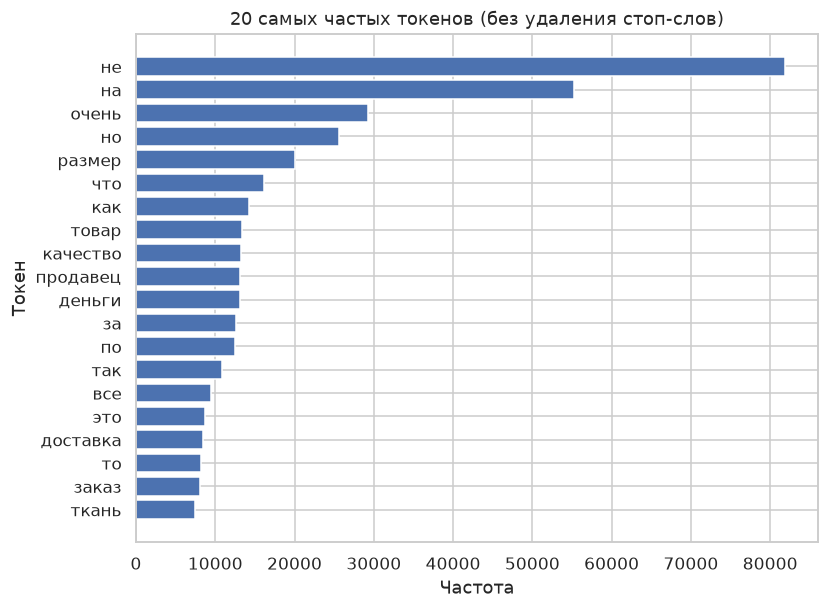

**negative**: деньги, товар, вернули, на, продавец, пришёл, пришел, очень, так, заказ, спор, что

**neutral**: на, очень, но, размер, качество, как, деньги, товар, по, ткань, соответствует, что

**positive**: на, очень, спасибо, качество, размер, доставка, супер, все, но, отлично, за, хорошо

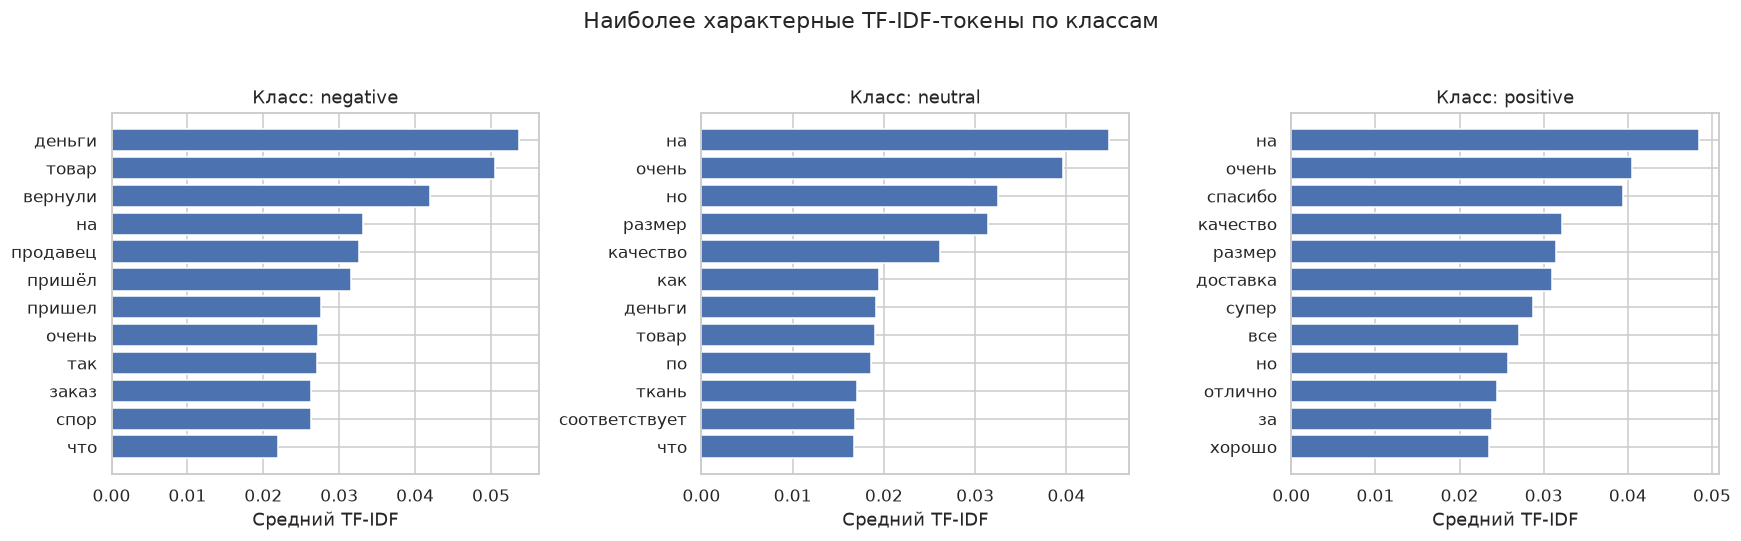

,Показатель,Значение
0,Средняя доля кириллицы,0.790
1,Средняя доля латиницы,0.013
2,Отзывов без кириллицы,1262.000
3,Отзывов без кириллицы вне mojibake,1243.000
4,Отзывов с mojibake,19.000
5,Отзывов с URL,128.000
6,Отзывов с цифрами,31874.000


Отзывов с отрицаниями (`не`, `нет`, `ни`, `никогда`): **50 087** (55.7 %). Отрицания не удалялись.

In [8]:
TOKEN_PATTERN = r"(?u)\b[а-яёa-z]{2,}\b"

count_vectorizer = CountVectorizer(
    lowercase=True,
    token_pattern=TOKEN_PATTERN,
    max_features=50_000,
)
count_matrix = count_vectorizer.fit_transform(df["review"].fillna(""))
count_terms = count_vectorizer.get_feature_names_out()
count_totals = np.asarray(count_matrix.sum(axis=0)).ravel()
top_indices = np.argsort(count_totals)[-20:][::-1]
top_tokens = pd.DataFrame(
    {
        "Токен": count_terms[top_indices],
        "Частота": count_totals[top_indices].astype(int),
    }
)
display(top_tokens)

fig, ax = plt.subplots(figsize=(8, 6))
plot_data = top_tokens.sort_values("Частота")
ax.barh(plot_data["Токен"], plot_data["Частота"], color="#4C72B0")
ax.set_title("20 самых частых токенов (без удаления стоп-слов)")
ax.set_xlabel("Частота")
ax.set_ylabel("Токен")
save_figure(fig, "04_top_tokens_overall.png")
plt.show()

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=TOKEN_PATTERN,
    min_df=5,
    max_df=0.5,
    sublinear_tf=True,
    max_features=50_000,
)
tfidf_matrix = tfidf_vectorizer.fit_transform(df["review"].fillna(""))
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
class_top_terms = {}
for class_name in CLASS_ORDER:
    mask = (df["sentiment"] == class_name).to_numpy()
    mean_scores = np.asarray(tfidf_matrix[mask].mean(axis=0)).ravel()
    top_idx = np.argsort(mean_scores)[-12:][::-1]
    class_top_terms[class_name] = pd.DataFrame(
        {
            "Токен": tfidf_terms[top_idx],
            "Средний TF-IDF": mean_scores[top_idx],
        }
    )
    display(
        Markdown(
            f"**{class_name}**: "
            + ", ".join(class_top_terms[class_name]["Токен"].tolist())
        )
    )

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, class_name in zip(axes, CLASS_ORDER):
    data = class_top_terms[class_name].sort_values("Средний TF-IDF")
    ax.barh(data["Токен"], data["Средний TF-IDF"], color="#4C72B0")
    ax.set_title(f"Класс: {class_name}")
    ax.set_xlabel("Средний TF-IDF")
    ax.set_ylabel("")
fig.suptitle("Наиболее характерные TF-IDF-токены по классам")
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(fig, "05_tfidf_terms_by_class.png")
plt.show()

cyrillic_count = df["review"].str.count(r"[А-Яа-яЁё]")
latin_count = df["review"].str.count(r"[A-Za-z]")
language_table = pd.DataFrame(
    [
        {
            "Показатель": "Средняя доля кириллицы",
            "Значение": round(float((cyrillic_count / df["char_len"]).mean()), 3),
        },
        {
            "Показатель": "Средняя доля латиницы",
            "Значение": round(float((latin_count / df["char_len"]).mean()), 3),
        },
        {
            "Показатель": "Отзывов без кириллицы",
            "Значение": int((cyrillic_count == 0).sum()),
        },
        {
            "Показатель": "Отзывов без кириллицы вне mojibake",
            "Значение": quality_stats["no_cyrillic_without_mojibake"],
        },
        {
            "Показатель": "Отзывов с mojibake",
            "Значение": quality_stats["mojibake_rows"],
        },
        {
            "Показатель": "Отзывов с URL",
            "Значение": int(quality_stats["urls"]),
        },
        {
            "Показатель": "Отзывов с цифрами",
            "Значение": int(quality_stats["digits"]),
        },
    ]
)
display(language_table)

negation_mask = df["review"].str.contains(
    r"\b(?:не|нет|ни|никогда)\b",
    case=False,
    regex=True,
    na=False,
)
negation_count = int(negation_mask.sum())
display(
    Markdown(
        f"Отзывов с отрицаниями (`не`, `нет`, `ни`, `никогда`): "
        f"**{fmt_int(negation_count)}** ({fmt_pct(negation_count / len(df) * 100)}). "
        "Отрицания не удалялись."
    )
)

### Результат

В общих частотах доминируют короткие служебные и общеупотребительные слова; это ожидаемо, потому что стоп-слова не удалялись. TF-IDF-усреднение по классам выводит на первый план лексику с наибольшим средним TF-IDF в каждом классе; это ассоциации, а не доказательство полярности. Отрицания `не`, `нет`, `ни`, `никогда` сохраняются; их содержит 50 087 отзывов (55.65 %). Латиница встречается в части текстов, но большинство символов — кириллица: средняя доля кириллицы — 0.790, латиницы — 0.013.

### Интерпретация

- Частотные слова описывают корпус, но не являются причиной класса. TF-IDF-термины — ассоциации в данной выборке, а не доказательство полярности.
- Токенизация: нижний регистр, regex-токены длиной от 2 символов, без лемматизации и без стоп-слов. Односимвольные слова и пунктуация отбрасываются; разные словоформы считаются разными токенами.
- Отрицания не удаляются, потому что они могут менять полярность. Для будущих моделей это нужно сохранить или обрабатывать явно.
- Наличие латиницы и URL не означает, что тексты не на русском: это могут быть размеры, бренды и ссылки. Отдельный языковой детектор не применялся. Из 1 262 отзывов без кириллицы 19 — mojibake; остальные 1 243 не классифицировались по языку.
- TF-IDF и частоты не используются для обучения модели в этом ноутбуке.

### Вывод

Лексический анализ даёт описательные ориентиры для future preprocessing, но не готовое правило очистки. При моделировании нужно отдельно решить вопросы лемматизации, стоп-слов, отрицаний и нормализации словоформ.

## 8. Связь меток с характеристиками данных

### Цель

Проверить, какие метаданные фактически есть, и сравнить производные характеристики текста по классам. Не считать корреляцию причинностью и не удалять поля без основания.

,char_len,word_count_ws,n_exclam,n_question,n_digits,upper_ratio,latin_ratio
sentiment,,,,,,,
negative,99.0,15.0,0.0,0.0,0.0,0.016,0.0
neutral,87.0,13.0,0.0,0.0,0.0,0.016,0.0
positive,89.0,13.0,0.0,0.0,0.0,0.022,0.0


,Класс,"Доля с URL, %"
0,negative,0.04
1,neutral,0.07
2,positive,0.32


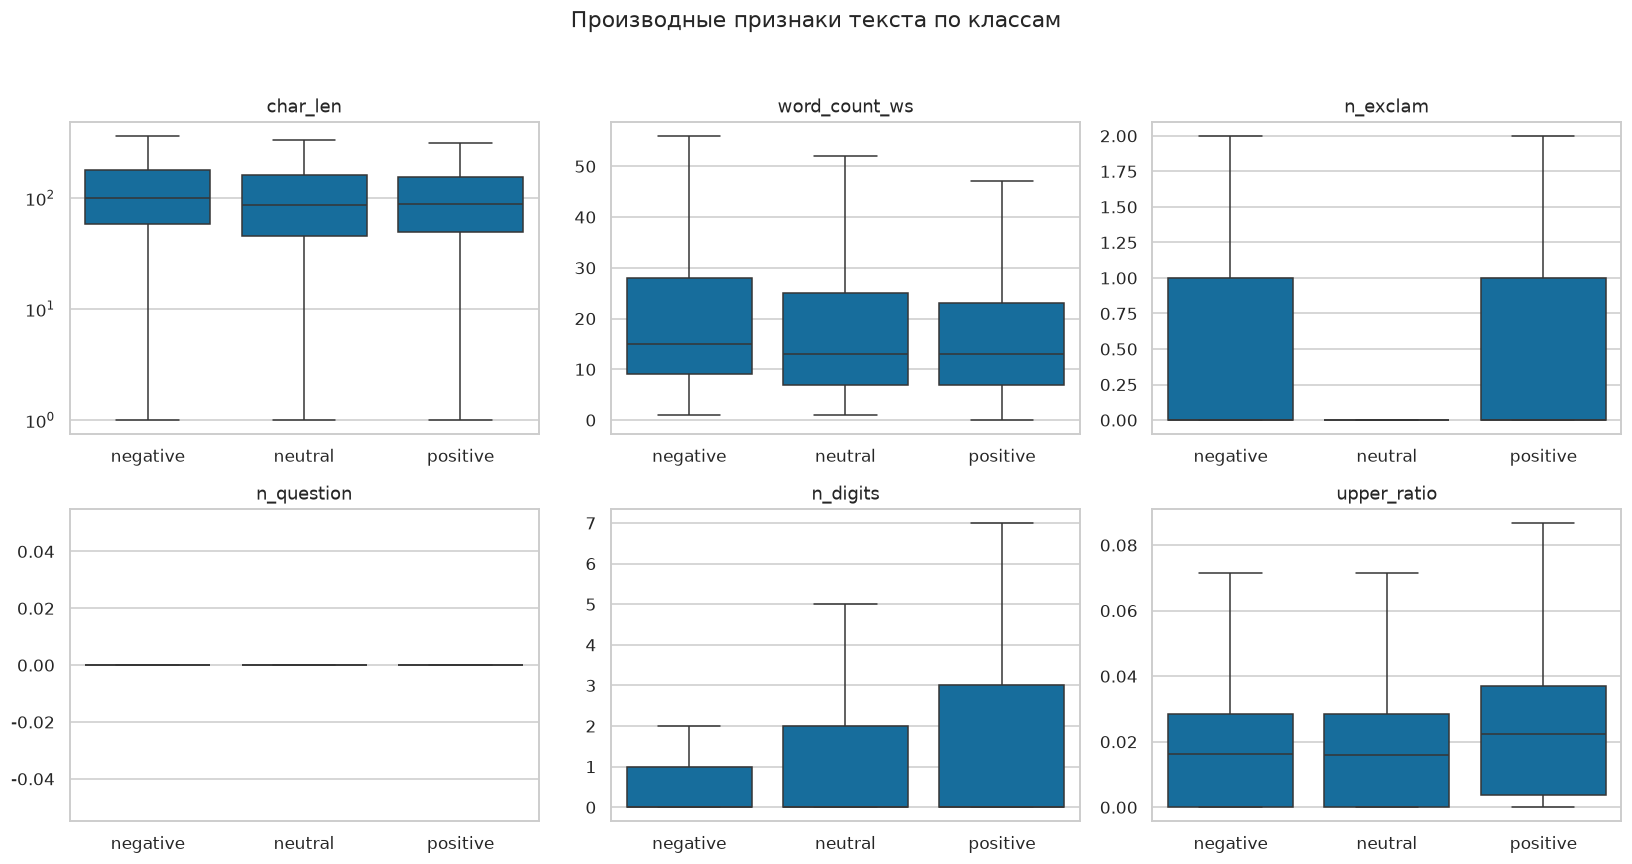

In [9]:
df["n_exclam"] = df["review"].str.count("!")
df["n_question"] = df["review"].str.count(r"\?")
df["n_digits"] = df["review"].str.count(r"\d")
df["n_upper"] = df["review"].str.count(r"[A-ZА-ЯЁ]")
df["upper_ratio"] = (df["n_upper"] / df["char_len"]).fillna(0.0)
df["n_latin"] = df["review"].str.count(r"[A-Za-z]")
df["latin_ratio"] = (df["n_latin"] / df["char_len"]).fillna(0.0)
df["has_url"] = df["review"].str.contains(
    r"https?://|www\.",
    case=False,
    regex=True,
    na=False,
)

feature_columns = [
    "char_len",
    "word_count_ws",
    "n_exclam",
    "n_question",
    "n_digits",
    "upper_ratio",
    "latin_ratio",
]
feature_medians = (
    df.groupby("sentiment", observed=True)[feature_columns]
    .median()
    .reindex(CLASS_ORDER)
)
display(feature_medians.round(3))

url_share = df.groupby("sentiment", observed=True)["has_url"].mean().reindex(CLASS_ORDER)
display(
    pd.DataFrame(
        {
            "Класс": CLASS_ORDER,
            "Доля с URL, %": [
                round(float(url_share[class_name]) * 100, 2) for class_name in CLASS_ORDER
            ],
        }
    )
)

plot_features = [
    "char_len",
    "word_count_ws",
    "n_exclam",
    "n_question",
    "n_digits",
    "upper_ratio",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), plot_features):
    sns.boxplot(
        data=df,
        x="sentiment",
        y=feature,
        order=CLASS_ORDER,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if feature == "char_len":
        ax.set_yscale("log")
fig.suptitle("Производные признаки текста по классам")
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(fig, "06_text_features_by_class.png")
plt.show()

### Результат

В файле нет рейтинга, категории, даты, идентификатора товара или пользователя — только `review` и `sentiment`. Сравнение по классам возможно только для производных признаков текста: длины, числа слов, восклицательных и вопросительных знаков, цифр, доли заглавных букв, доли латиницы и наличия URL.

### Интерпретация

- Метаданных для анализа категорий, времени или источника нет; такие выводы сделать нельзя.
- Различия производных признаков по классам описательные. Например, negative-отзывы длиннее; это может быть связано с описанием проблем, но не доказывает причинность.
- Признаки вычислены из текста, а не из внешней разметки, поэтому сами по себе не являются утечкой метки. Основной риск утечки — одинаковые или почти одинаковые тексты в train и test.
- Поля не удаляются: даже если признак не используется в модели, он может быть полезен для диагностики.

### Вывод

Отдельного анализа метаданных не будет из-за их отсутствия. Для будущего моделирования основной мерой против утечки остаётся group-aware split по тексту; производные признаки можно использовать только после проверки на пересечения и без причинных интерпретаций.

## 9. Репрезентативность и ограничения

### Цель

Явно разделить то, что можно установить по данным, и то, что остаётся неизвестным.

### Что установлено

- Датасет относится к одной категории — «Women’s Clothes and Accessories»; по README отзывы собраны по top-ranked товарам крупного e-commerce сайта.
- Метки автоматически получены из пользовательских оценок и затем сжаты в 3 класса; в файле нет исходного рейтинга, поэтому восстановить точное соответствие оценок классам нельзя.
- Balanced-файл содержит по 30 000 записей на класс; это результат undersampling’а, а не естественное распределение.
- В файле нет дат, категорий, идентификаторов товаров/пользователей и исходных train/validation/test-разбиений.
- Есть дубликаты, почти-дубликаты и тексты с разными метками; это влияет на оценку качества и риск утечки.
- Формат файла нестандартный: многострочные отзывы и табуляция внутри текста требуют проверенного парсера.
- В 19 строках обнаружен восстановимый mojibake (`latin-1` вместо `UTF-8`); 1 262 отзыва не содержат кириллицы, их язык отдельно не классифицировался.

### Что не установлено

- Точное соответствие оценок 1–5 классам negative/neutral/positive: формулировка README неполная, требуется проверка по статье или исходным данным.
- Естественная распространённость классов в генеральной совокупности: balanced-файл для этого не подходит.
- Репрезентативность для всех русскоязычных отзывов, других категорий товаров и других периодов времени.
- Корректность автоматической разметки и доля ошибок меток без ручной проверки.
- Наличие персональных данных в текстах: отдельный PII-аудит не проводился.
- Доступность полного набора на 821 000 отзывов: в master-репозитории опубликован только balanced-файл.

### Ограничения лицензии и данных

Лицензия репозитория — Apache-2.0. Исходный CSV не коммитится в Git: каталог `data/` уже игнорируется. Примеры текстов в ноутбуке обрезаются; полные отзывы не публикуются. При использовании данных нужно сохранить ссылку на источник, лицензию и цитирование статьи.

### Вывод

Результаты EDA относятся к опубликованному balanced-файлу RuReviews и не переносятся автоматически на другие домены, периоды или естественное распределение классов. Все дальнейшие выводы о качестве моделей должны учитывать эти ограничения.

## 10. Итоги EDA и решения

### Цель

Свести подтверждённые результаты, риски и решения в одну таблицу, сохранить машинно-читаемые метрики и зафиксировать следующие шаги.

In [11]:
metrics = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "environment": ENV,
    "source": {
        "name": "RuReviews",
        "url": SOURCE_URL,
        "commit": SOURCE_COMMIT,
        "license": LICENSE_NAME,
        "license_url": LICENSE_URL,
        "paper_doi": PAPER_DOI,
        "access_date": ACCESS_DATE,
        "file": DATA_PATH.name,
        "local_path": str(DATA_PATH.relative_to(PROJECT_ROOT)),
        "size_bytes": int(len(raw_bytes)),
        "sha256": sha256,
        "git_blob_sha": git_blob,
        "source_columns": ["review", "sentiment"],
        "diagnostic_columns": [
            "sentiment_raw",
            "sentiment",
            "line_start",
            "line_end",
            "n_physical_lines",
        ],
        "physical_lines": int(len(physical_lines)),
        "line_endings": {
            "crlf": int(format_stats["crlf"]),
            "lf": int(format_stats["lf"]),
            "cr_only": int(format_stats["cr_only"]),
            "nel": int(format_stats["nel"]),
        },
    },
    "dataset": {
        "rows": int(len(df)),
        "columns_in_file": 2,
        "columns_in_dataframe_at_load": int(loaded_shape[1]),
        "class_counts_raw": {key: int(value) for key, value in raw_label_counts.items()},
        "class_counts": {class_name: int(class_counts[class_name]) for class_name in CLASS_ORDER},
        "multiline_records": multiline_records,
        "tab_records": tab_records,
        "whitespace_only_records": whitespace_only,
    },
    "quality": quality_stats,
    "duplicates": {
        "exact_duplicate_rows": exact_dup_rows,
        "exact_duplicate_groups": exact_dup_groups,
        "duplicate_text_rows": text_dup_rows,
        "unique_texts": unique_texts,
        "texts_with_multiple_labels": multi_label_texts,
        "normalized_duplicate_rows": norm_dup_rows,
        "normalized_duplicate_groups": norm_dup_groups,
    },
    "split_diagnostic": {
        "type": "hypothetical stratified 80/20 random split; not a final split",
        "test_rows": int(len(test_part)),
        "exact_text_overlap_rows": test_text_overlap,
        "exact_text_overlap_share_pct": round(test_text_overlap / len(test_part) * 100, 2),
        "normalized_text_overlap_rows": test_norm_overlap,
        "normalized_text_overlap_share_pct": round(test_norm_overlap / len(test_part) * 100, 2),
    },
    "text_length": {
        "chars": {key: float(value) for key, value in length_overall.loc["char_len"].items()},
        "chars_by_class": {
            class_name: {
                key: float(value) for key, value in by_class.loc[class_name].items()
            }
            for class_name in CLASS_ORDER
        },
        "words_by_class": {
            class_name: {
                key: float(value) for key, value in words_by_class.loc[class_name].items()
            }
            for class_name in CLASS_ORDER
        },
    },
    "lexical": {
        "top_tokens_overall": top_tokens.head(20).to_dict(orient="records"),
        "tfidf_top_terms_by_class": {
            class_name: class_top_terms[class_name].to_dict(orient="records")
            for class_name in CLASS_ORDER
        },
        "negation_reviews": negation_count,
        "negation_share_pct": round(negation_count / len(df) * 100, 2),
        "language": {
            row["Показатель"]: row["Значение"] for row in language_table.to_dict(orient="records")
        },
    },
    "text_features_medians_by_class": {
        class_name: {
            key: float(value) for key, value in feature_medians.loc[class_name].items()
        }
        for class_name in CLASS_ORDER
    },
    "optional_svd": {
        "sample_size": int(len(sample_df)),
        "explained_variance_2d": explained_variance_2d,
        "explained_variance_2d_pct": round(explained_variance_2d * 100, 2),
    },
    "artifacts": sorted(
        str(path.relative_to(PROJECT_ROOT)) for path in FIG_DIR.glob("*.png")
    ),
}
metrics_path = REPORT_DIR / "eda_metrics.json"
metrics_path.write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2, default=json_default),
    encoding="utf-8",
)

environment_lines = [
    "RuReviews EDA environment",
    f"generated_at_utc={metrics['generated_at']}",
    f"python={ENV['python']}",
    f"platform={ENV['platform']}",
    f"executable={ENV['executable']}",
    f"seed={SEED}",
    *[f"{name}={value}" for name, value in package_versions.items()],
]
(REPORT_DIR / "environment.txt").write_text(
    "\n".join(environment_lines) + "\n",
    encoding="utf-8",
)

summary_rows = [
    {
        "Наблюдение": "Пропуски",
        "Подтверждённый результат": (
            f"review: {int(df['review'].isna().sum())}; "
            f"sentiment_raw: {int(df['sentiment_raw'].isna().sum())}; "
            f"пустых: {quality_stats['exact_empty']}; "
            f"пробельных: {quality_stats['whitespace_only']}"
        ),
        "Риск/значение": "Один текст без содержания; остальные поля заполнены",
        "Рекомендуемое действие": "Пометить и исключить/обработать при моделировании; в EDA не удалять",
    },
    {
        "Наблюдение": "Дубликаты",
        "Подтверждённый результат": (
            f"точных дублей строк: {exact_dup_rows}; "
            f"дублей текста: {text_dup_rows}; "
            f"текстов с разными метками: {multi_label_texts}; "
            f"нормализованных дублей: {norm_dup_rows}"
        ),
        "Риск/значение": "Завышение метрик и утечка при случайном split",
        "Рекомендуемое действие": "Не удалять в EDA; при моделировании — group-aware split/дедупликация по обоснованному правилу",
    },
    {
        "Наблюдение": "Баланс классов",
        "Подтверждённый результат": (
            f"negative: {fmt_int(class_counts['negative'])}; "
            f"neutral: {fmt_int(class_counts['neutral'])}; "
            f"positive: {fmt_int(class_counts['positive'])}; "
            f"отношение max/min = {balance_ratio:.2f}"
        ),
        "Риск/значение": "Баланс получен undersampling’ом и не отражает естественное распределение",
        "Рекомендуемое действие": "Использовать macro-F1 и per-class метрики; не интерпретировать доли как распространённость",
    },
    {
        "Наблюдение": "Качество текста",
        "Подтверждённый результат": (
            f"многострочных: {multiline_records}; "
            f"с табуляцией: {tab_records}; "
            f"NEL: {format_stats['nel']}; "
            f"mojibake: {quality_stats['mojibake_rows']}; "
            f"NBSP/zero-width: {quality_stats['zero_width_or_nbsp']}; "
            f"HTML: {quality_stats['html_tags']}; "
            f"URL: {quality_stats['urls']}"
        ),
        "Риск/значение": "Нестандартный формат ломает наивный CSV-парсер; возможны артефакты токенизации",
        "Рекомендуемое действие": "Сохранить исходный файл; документировать парсер; при обучении использовать проверенную очистку",
    },
    {
        "Наблюдение": "Утечка данных",
        "Подтверждённый результат": (
            f"исходных split нет; в гипотетическом 80/20 split точное пересечение текста — "
            f"{test_text_overlap} строк ({test_text_overlap / len(test_part) * 100:.2f} %), "
            f"нормализованное — {test_norm_overlap} ({test_norm_overlap / len(test_part) * 100:.2f} %)"
        ),
        "Риск/значение": "Случайный split завысит оценку качества из-за дублей",
        "Рекомендуемое действие": "Финальный split делать group-aware по нормализованному тексту; проверить пересечения до обучения",
    },
    {
        "Наблюдение": "Метки",
        "Подтверждённый результат": (
            "negative, neautral (опечатка), positive; "
            "точное соответствие рейтингам 1–5 в README неполное"
        ),
        "Риск/значение": "Семантика neutral подтверждена контекстом, но маппинг рейтингов требует проверки",
        "Рекомендуемое действие": "Хранить sentiment_raw; использовать neutral в памяти; зафиксировать открытый вопрос в provenance",
    },
]
summary_table = pd.DataFrame(summary_rows)
display(summary_table)
display(
    Markdown(
        f"Метрики сохранены в `{metrics_path.relative_to(PROJECT_ROOT)}`; "
        f"графики — в `{FIG_DIR.relative_to(PROJECT_ROOT)}`."
    )
)

,Наблюдение,Подтверждённый результат,Риск/значение,Рекомендуемое действие
0,Пропуски,review: 0; sentiment_raw: 0; пустых: 0; пробельных: 1,Один текст без содержания; остальные поля заполнены,Пометить и исключить/обработать при моделировании; в EDA не удалять
1,Дубликаты,точных дублей строк: 2250; дублей текста: 2679; текстов с разными метками: 388; нормализованных дублей: 4959,Завышение метрик и утечка при случайном split,Не удалять в EDA; при моделировании — group-aware split/дедупликация по обоснованному правилу
2,Баланс классов,negative: 30 000; neutral: 30 000; positive: 30 000; отношение max/min = 1.00,Баланс получен undersampling’ом и не отражает естественное распределение,Использовать macro-F1 и per-class метрики; не интерпретировать доли как распространённость
3,Качество текста,многострочных: 4661; с табуляцией: 4; NEL: 14; mojibake: 19; NBSP/zero-width: 72; HTML: 1; URL: 128,Нестандартный формат ломает наивный CSV-парсер; возможны артефакты токенизации,Сохранить исходный файл; документировать парсер; при обучении использовать проверенную очистку
4,Утечка данных,"исходных split нет; в гипотетическом 80/20 split точное пересечение текста — 659 строк (3.66 %), нормализованное — 1...",Случайный split завысит оценку качества из-за дублей,Финальный split делать group-aware по нормализованному тексту; проверить пересечения до обучения
5,Метки,"negative, neautral (опечатка), positive; точное соответствие рейтингам 1–5 в README неполное","Семантика neutral подтверждена контекстом, но маппинг рейтингов требует проверки",Хранить sentiment_raw; использовать neutral в памяти; зафиксировать открытый вопрос в provenance


Метрики сохранены в `reports\eda_metrics.json`; графики — в `reports\figures`.

### Решения для следующего этапа

1. Сохранять исходный файл и `sentiment_raw`; нормализовать `neautral` в `neutral` только в памяти и документировать это.
2. Не удалять дубликаты в EDA. Перед обучением выбрать group-aware split по точному или нормализованному тексту и проверить пересечения train/test.
3. Исключить или отдельно обработать единственный пробельный отзыв; не импутировать его без объяснения.
4. Для оценки моделей использовать macro-F1, precision/recall по классам и матрицу ошибок; accuracy приводить только как дополнительную метрику.
5. Не интерпретировать баланс 30k/30k как естественное распределение и не использовать его для выводов о генеральной совокупности.
6. Для future preprocessing отдельно решить вопросы лемматизации, стоп-слов, отрицаний, URL, HTML и невидимых символов.
7. Не использовать полный набор 821k как доступный: в master-репозитории опубликован только balanced-файл; при необходимости запросить источник у авторов.
8. Синтетические данные и обучение моделей в этом ноутбуке не выполнялись; это следующий этап проекта.

### Созданные артефакты

- `notebooks/01_rureviews_eda.ipynb` — этот ноутбук;
- `reports/figures/01_class_balance.png` — баланс классов;
- `reports/figures/02_text_length_hist.png` — распределение длины;
- `reports/figures/03_text_length_by_class.png` — длина по классам;
- `reports/figures/04_top_tokens_overall.png` — частые токены;
- `reports/figures/05_tfidf_terms_by_class.png` — TF-IDF-термины;
- `reports/figures/06_text_features_by_class.png` — производные признаки;
- `reports/figures/07_tfidf_svd.png` — опциональная 2D-проекция;
- `reports/eda_metrics.json` — метрики EDA;
- `reports/environment.txt` — версии окружения.